# EV Battery Health Prediction: Step 3, Training SOH Models

In this notebook I train machine learning models to predict the **State of Health (SOH)** of lithium-ion batteries using the NASA Prognostics Center of Excellence battery aging dataset.

**What is SOH?**
SOH tells how much of its original capacity a battery still has.

`SOH (%) = current capacity / starting capacity x 100`

A fresh battery is close to 100%. In EV applications, a battery is usually treated as "worn out" once it drops to about 80%. So a model that predicts SOH from a battery's discharge behaviour can tell an EV owner or fleet operator how healthy the battery is without running a full capacity test.

**Where this fits in the project**

| Step | What I did |
|---|---|
| 1 | Loaded the NASA `.mat` files and plotted the capacity fade of B0005 |
| 2 | Combined 4 batteries (B0005, B0006, B0007, B0018) and explored the data |
| **3 (this notebook)** | **Train and compare models to predict SOH** |
| 4 | Explain the best model with SHAP |
| 5 | Predict Remaining Useful Life (RUL) |
| 6 | Build and deploy a Streamlit app |

## 1. Objective

Predict the SOH (%) of a battery at a given discharge cycle, using only measurements taken during that discharge (voltage, current, temperature and discharge time).

This is a **regression** problem because the target is a continuous number.

## 2. Importing libraries

- `pandas`, `numpy` for the data
- `matplotlib` for plots
- `scikit-learn` for Linear Regression, Random Forest and the evaluation metrics
- `xgboost` for the gradient boosting model

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

## 3. Loading the data

`all_batteries.csv` is the file I created in Step 2. It has **one row per discharge cycle** for each battery, with features summarised from the raw voltage, current and temperature readings.

In [11]:
df = pd.read_csv("all_batteries.csv")

print("Shape:", df.shape)
print()
print("Discharge cycles per battery:")
print(df["battery"].value_counts())
df.head()

Shape: (636, 10)

Discharge cycles per battery:
battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64


,cycle,capacity_ah,avg_voltage,min_voltage,avg_current,avg_temp,max_temp,discharge_time_s,soh_percent,battery
0,1,1.856487,3.529829,2.612467,-1.818702,32.572328,38.982181,3690.234,100.000000,B0005
1,2,1.846327,3.537320,2.587209,-1.817560,32.725235,39.033398,3672.344,99.452721,B0005
2,3,1.835349,3.543737,2.651917,-1.816487,32.642862,38.818797,3651.641,98.861386,B0005
3,4,1.835263,3.543666,2.592948,-1.825589,32.514876,38.762305,3631.563,98.856718,B0005
4,5,1.834646,3.542343,2.547420,-1.826114,32.382349,38.665393,3629.172,98.823482,B0005


## 4. Features and target

**Target:** `soh_percent`

**Features** (all calculated from one discharge cycle):

| Feature | What it represents |
|---|---|
| `avg_voltage` | Average terminal voltage during the discharge |
| `min_voltage` | Lowest voltage reached |
| `avg_current` | Average discharge current |
| `avg_temp` | Average battery temperature |
| `max_temp` | Peak battery temperature |
| `discharge_time_s` | How long the discharge lasted (seconds) |

I left out `cycle` (the cycle number) on purpose. A real EV does not always know exactly how many cycles its battery has been through, and a model that depends on it would not be practical. Later in this notebook I compare the results with and without it, to see how much it matters.

In [12]:
TARGET = "soh_percent"

FEATURES = [
    "avg_voltage",
    "min_voltage",
    "avg_current",
    "avg_temp",
    "max_temp",
    "discharge_time_s",
]

## 5. Train and test split: by battery, not randomly

I trained on three batteries (**B0005, B0006, B0007**) and tested on a fourth one (**B0018**) that the model never saw during training.

**Why not a random split?**
Consecutive cycles of the same battery are almost identical. With a random split, cycle 50 could be in the training set and cycle 51 in the test set, so the model would be tested on something it has practically already seen. That gives scores that look great but are not honest.

Testing on a completely different battery is closer to the real use case, where a model has to judge a battery it has never encountered.

In [13]:
TRAIN_BATTERIES = ["B0005", "B0006", "B0007"]
TEST_BATTERY = "B0018"

train = df[df["battery"].isin(TRAIN_BATTERIES)]
test = df[df["battery"] == TEST_BATTERY]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Training rows: {len(train)}  (batteries: {', '.join(TRAIN_BATTERIES)})")
print(f"Testing rows:  {len(test)}  (battery: {TEST_BATTERY})")

Training rows: 504  (batteries: B0005, B0006, B0007)
Testing rows:  132  (battery: B0018)


## 6. Models

I tried three models, from simple to more complex:

| Model | Why I chose it |
|---|---|
| **Linear Regression** | A simple baseline. Battery fade is fairly smooth, so a straight-line relationship may already capture a lot. Any other model has to beat this to be worth the extra complexity. |
| **Random Forest** | Many decision trees averaged together. It can capture non-linear patterns and is hard to overfit badly. |
| **XGBoost** | Gradient boosting, where each new tree corrects the errors of the previous ones. It is a popular choice for tabular data. |

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42
    ),
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append(
        {
            "Model": name,
            "MAE (SOH %)": mean_absolute_error(y_test, pred),
            "RMSE (SOH %)": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred),
        }
    )

results_df = pd.DataFrame(results).round(3)
results_df.to_csv("model_results.csv", index=False)

## 7. Evaluation

I used three metrics on the unseen battery:

| Metric | Meaning | Good sign |
|---|---|---|
| **MAE** | Average error in SOH percentage points. MAE = 2 means the prediction is about 2 points off on average. | Lower is better |
| **RMSE** | Similar to MAE, but large mistakes are penalised more heavily. | Lower is better |
| **R2** | How much of the variation in SOH the model explains. | Closer to 1 is better |

In [15]:
results_df.sort_values("RMSE (SOH %)").reset_index(drop=True)

,Model,MAE (SOH %),RMSE (SOH %),R2
0,XGBoost,1.882,2.319,0.922
1,Random Forest,2.133,2.804,0.886
2,Linear Regression,5.315,5.362,0.584


In [16]:
best = results_df.sort_values("RMSE (SOH %)").iloc[0]
print(f"Lowest RMSE on {TEST_BATTERY}: {best['Model']}")
print(f"  MAE  = {best['MAE (SOH %)']} SOH points")
print(f"  RMSE = {best['RMSE (SOH %)']} SOH points")
print(f"  R2   = {best['R2']}")

Lowest RMSE on B0018: XGBoost
  MAE  = 1.882 SOH points
  RMSE = 2.319 SOH points
  R2   = 0.922


## 8. Predicted vs actual SOH

The black line is the real SOH of the unseen battery. The dashed lines are what each model predicted. The closer a dashed line follows the black one, the better the model.

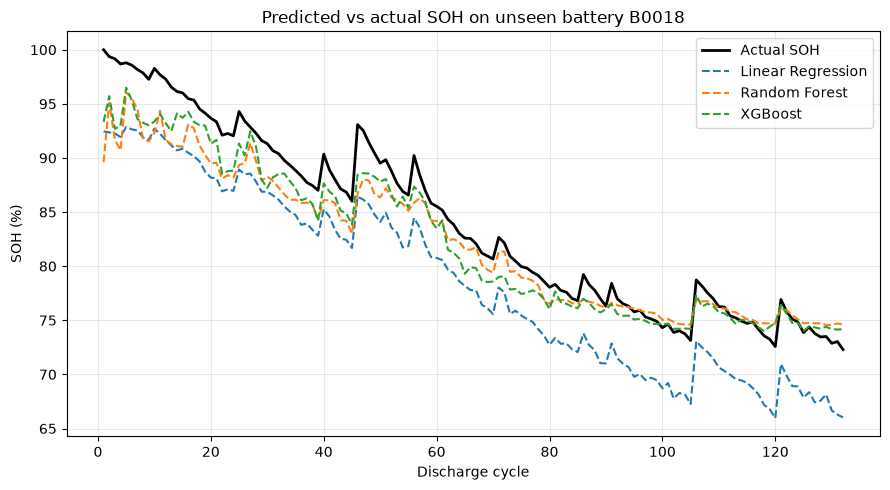

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(test["cycle"].values, y_test.values, color="black", linewidth=2, label="Actual SOH")

for name, pred in predictions.items():
    plt.plot(test["cycle"].values, pred, linestyle="--", label=name)

plt.title(f"Predicted vs actual SOH on unseen battery {TEST_BATTERY}")
plt.xlabel("Discharge cycle")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=150)
plt.show()

## 9. Does the cycle number help?

Earlier I excluded `cycle` because a real EV may not know it. Here I train XGBoost twice, once without it and once with it, to see how much information it adds.

If the score improves a lot, the model is leaning heavily on "how old is the battery". If it barely changes, the voltage, current and temperature features already carry most of the useful signal, which is a better result for a practical system.

In [18]:
rows = []

for use_cycle in [False, True]:
    feats = FEATURES + (["cycle"] if use_cycle else [])

    m = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
    m.fit(train[feats], y_train)
    p = m.predict(test[feats])

    rows.append(
        {
            "Features": "With cycle" if use_cycle else "Without cycle",
            "MAE (SOH %)": mean_absolute_error(y_test, p),
            "RMSE (SOH %)": np.sqrt(mean_squared_error(y_test, p)),
            "R2": r2_score(y_test, p),
        }
    )

pd.DataFrame(rows).round(3)

,Features,MAE (SOH %),RMSE (SOH %),R2
0,Without cycle,1.882,2.319,0.922
1,With cycle,1.819,2.310,0.923


## 10. Limitations to keep in mind

- **Only one test battery.** B0018 is a single battery, so the scores are one data point, not a guarantee. A fuller check would rotate which battery is held out (leave-one-battery-out).
- **Small dataset.** Each battery has well under 200 discharge cycles.
- **Different test conditions.** The NASA batteries were discharged until the voltage reached preset thresholds, and these thresholds may differ between batteries. Features like `discharge_time_s` can therefore behave differently from one battery to another, which may affect how well a model transfers to a new battery.
- **Lab data, not real driving.** These are controlled lab cycles. Real EV usage is much more varied.

## 11. Next step

In Step 4 I will use **SHAP** to explain which features the best model relies on, and check whether those make sense physically (for example, lower discharge time should go with lower SOH).